# Customer Churn Analysis

**Goal:** find out *why* customers leave a telecom provider and *which* customers are most at risk, so the retention team can act before they churn.

**Steps**
1. Load and clean the data
2. Explore churn with SQL
3. Visualise the main churn drivers
4. Build a simple model to score churn risk
5. Recommendations

## 1. Load and clean the data

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
IMG = Path("../images")
IMG.mkdir(exist_ok=True)

df = pd.read_csv("../data/telco_customers.csv")
print(df.shape)
df.head()

(7000, 14)


,customer_id,gender,senior_citizen,partner,tenure_months,contract,internet_service,tech_support,paperless_billing,payment_method,monthly_charges,total_charges,support_calls,churn
0,CUST-00001,Male,1,No,1,One year,Fiber optic,No,Yes,Mailed check,89.97,88.55,2,No
1,CUST-00002,Female,0,No,12,Month-to-month,DSL,No,Yes,Electronic check,63.52,725.88,2,Yes
2,CUST-00003,Female,0,Yes,33,Two year,DSL,No,Yes,Bank transfer,61.50,1960.58,1,No
3,CUST-00004,Female,0,No,33,One year,DSL,No,Yes,Bank transfer,54.71,1740.04,0,No
4,CUST-00005,Female,0,Yes,21,Month-to-month,DSL,Yes,No,Mailed check,50.21,1023.87,1,No


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7000 non-null   str    
 1   gender             7000 non-null   str    
 2   senior_citizen     7000 non-null   int64  
 3   partner            7000 non-null   str    
 4   tenure_months      7000 non-null   int64  
 5   contract           7000 non-null   str    
 6   internet_service   7000 non-null   str    
 7   tech_support       7000 non-null   str    
 8   paperless_billing  7000 non-null   str    
 9   payment_method     7000 non-null   str    
 10  monthly_charges    7000 non-null   float64
 11  total_charges      7000 non-null   str    
 12  support_calls      7000 non-null   int64  
 13  churn              7000 non-null   str    
dtypes: float64(1), int64(3), str(10)
memory usage: 765.8 KB


`total_charges` was read as text because some rows contain a blank space. Those are brand-new customers with no bill yet, so I convert the column to numbers and fill the blanks with 0.

In [3]:
df["total_charges"] = pd.to_numeric(df["total_charges"].str.strip(), errors="coerce")
print("Blank total_charges:", df["total_charges"].isna().sum())
df["total_charges"] = df["total_charges"].fillna(0)

print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())
df["churn_flag"] = (df["churn"] == "Yes").astype(int)
df.describe().round(2)

Blank total_charges: 11
Duplicate customer IDs: 0


,senior_citizen,tenure_months,monthly_charges,total_charges,support_calls,churn_flag
count,7000.00,7000.00,7000.00,7000.00,7000.00,7000.00
mean,0.16,29.35,59.08,1709.77,1.61,0.26
std,0.36,18.73,24.13,1380.09,1.26,0.44
min,0.00,1.00,18.00,0.00,0.00,0.00
25%,0.00,15.00,40.08,628.06,1.00,0.00
50%,0.00,28.00,62.08,1370.01,1.00,0.00
75%,0.00,43.00,78.30,2494.76,2.00,1.00
max,1.00,72.00,120.00,8399.87,9.00,1.00


## 2. Explore churn with SQL

I load the clean data into an in-memory SQLite database and run the queries saved in `sql/churn_queries.sql`.

In [4]:
con = sqlite3.connect(":memory:")
df.drop(columns="churn_flag").to_sql("customers", con, index=False)

queries = [q.strip() for q in Path("../sql/churn_queries.sql").read_text().split(";") if "SELECT" in q]
titles = ["Overall churn", "By contract", "By tenure band", "By payment method",
          "Revenue lost by internet service", "High-risk segment", "Support calls"]

results = {}
for title, q in zip(titles, queries):
    results[title] = pd.read_sql(q, con)
    print(f"\n--- {title} ---")
    print(results[title].to_string(index=False))


--- Overall churn ---
 total_customers  churned  churn_rate_pct
            7000     1827            26.1

--- By contract ---
      contract  customers  churn_rate_pct
Month-to-month       3897            40.7
      One year       1665            12.1
      Two year       1438             2.6

--- By tenure band ---
 tenure_band  customers  churn_rate_pct
 0-12 months       1511            48.4
13-24 months       1548            36.2
25-48 months       2699            18.3
49-72 months       1242             3.4

--- By payment method ---
  payment_method  customers  churn_rate_pct
Electronic check       2301            32.1
    Mailed check       1580            23.9
   Bank transfer       1566            23.6
     Credit card       1553            22.0

--- Revenue lost by internet service ---
internet_service  monthly_revenue_lost  share_of_loss_pct
     Fiber optic               85723.0               70.7
             DSL               27828.0               23.0
     No internet 

## 3. Visualise the churn drivers

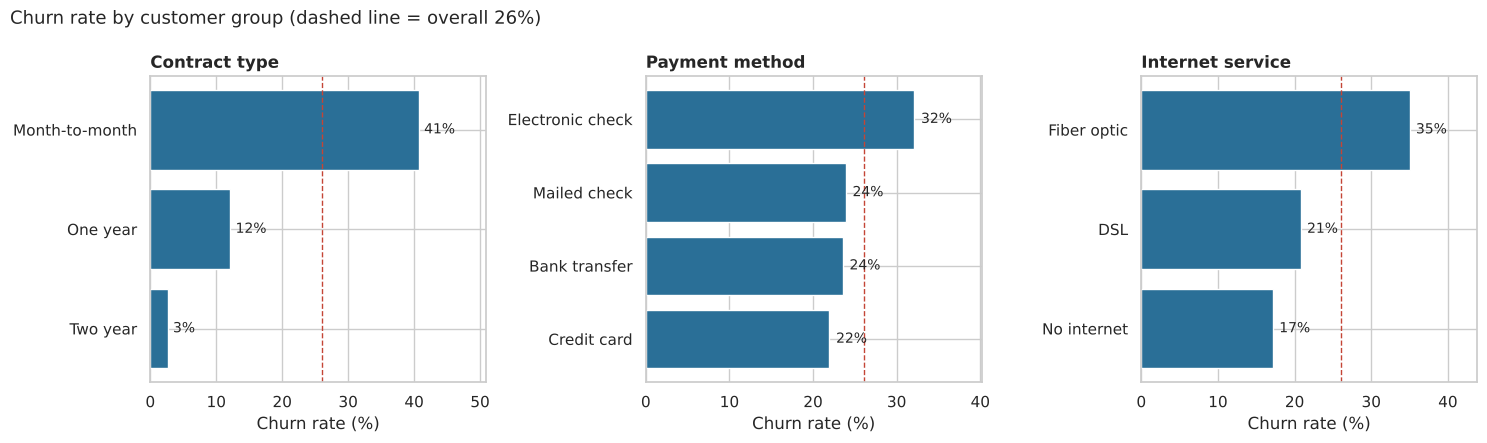

In [5]:
def churn_rate(col, order=None):
    s = df.groupby(col)["churn_flag"].mean().mul(100)
    return s.reindex(order) if order else s.sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
panels = [
    ("contract", ["Month-to-month", "One year", "Two year"], "Contract type"),
    ("payment_method", None, "Payment method"),
    ("internet_service", None, "Internet service"),
]
overall = df["churn_flag"].mean() * 100
for ax, (col, order, title) in zip(axes, panels):
    s = churn_rate(col, order)
    ax.barh(s.index[::-1], s.values[::-1], color="#2a6f97")
    ax.axvline(overall, color="#c44536", ls="--", lw=1)
    for i, v in enumerate(s.values[::-1]):
        ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=10)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel("Churn rate (%)")
    ax.set_xlim(0, max(s.max() * 1.25, 10))
fig.suptitle(f"Churn rate by customer group (dashed line = overall {overall:.0f}%)", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.savefig(IMG / "churn_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

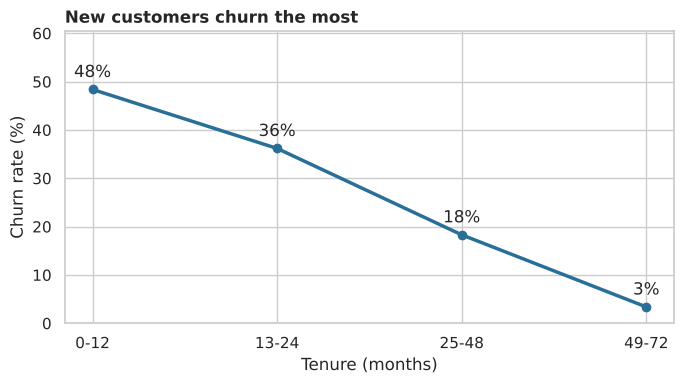

In [6]:
bins = [0, 12, 24, 48, 72]
labels = ["0-12", "13-24", "25-48", "49-72"]
df["tenure_band"] = pd.cut(df["tenure_months"], bins=bins, labels=labels)
tenure = df.groupby("tenure_band", observed=True)["churn_flag"].mean().mul(100)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tenure.index.astype(str), tenure.values, marker="o", color="#2a6f97", lw=2.5)
for x, y in zip(tenure.index.astype(str), tenure.values):
    ax.annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 9), ha="center")
ax.set_title("New customers churn the most", loc="left", fontweight="bold")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, tenure.max() * 1.25)
plt.tight_layout()
plt.savefig(IMG / "churn_by_tenure.png", dpi=150, bbox_inches="tight")
plt.show()

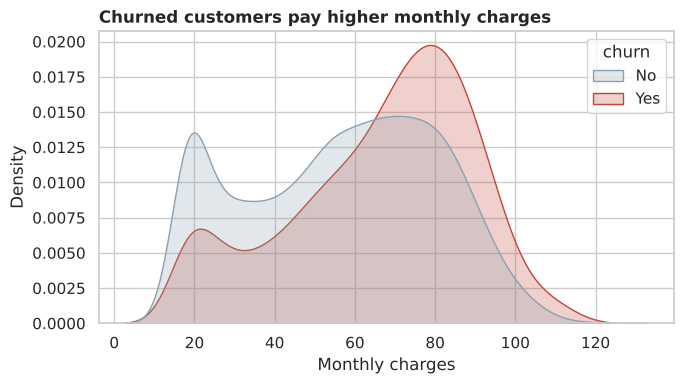

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(data=df, x="monthly_charges", hue="churn", fill=True, common_norm=False,
            palette={"No": "#8aa1b1", "Yes": "#c44536"}, ax=ax)
ax.set_title("Churned customers pay higher monthly charges", loc="left", fontweight="bold")
ax.set_xlabel("Monthly charges")
plt.tight_layout()
plt.savefig(IMG / "monthly_charges_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Churn risk model

A logistic regression keeps the model easy to explain to business users; a random forest is a comparison point.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

features = ["tenure_months", "monthly_charges", "support_calls", "senior_citizen",
            "contract", "internet_service", "tech_support", "payment_method", "paperless_billing"]
X = pd.get_dummies(df[features], drop_first=True, dtype=int)
y = df["churn_flag"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42)
forest.fit(X_train, y_train)

for name, model in [("Logistic regression", logreg), ("Random forest", forest)]:
    p = model.predict_proba(X_test)[:, 1]
    print(f"{name}: ROC-AUC = {roc_auc_score(y_test, p):.3f}")

print()
print(classification_report(y_test, logreg.predict(X_test), target_names=["Stayed", "Churned"]))

Logistic regression: ROC-AUC = 0.827
Random forest: ROC-AUC = 0.807

              precision    recall  f1-score   support

      Stayed       0.82      0.91      0.86      1293
     Churned       0.63      0.44      0.51       457

    accuracy                           0.79      1750
   macro avg       0.72      0.67      0.69      1750
weighted avg       0.77      0.79      0.77      1750



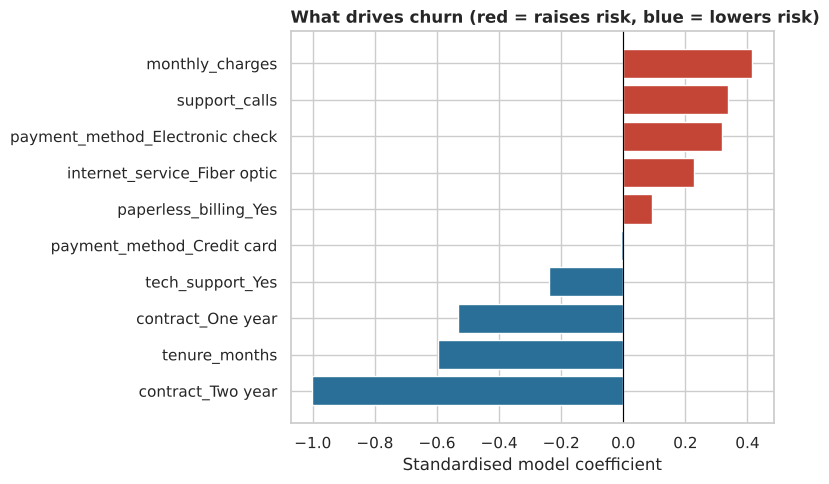

In [9]:
coefs = pd.Series(logreg[-1].coef_[0], index=X.columns).sort_values()
top = pd.concat([coefs.head(5), coefs.tail(5)])

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#2a6f97" if v < 0 else "#c44536" for v in top.values]
ax.barh(top.index, top.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("What drives churn (red = raises risk, blue = lowers risk)", loc="left", fontweight="bold")
ax.set_xlabel("Standardised model coefficient")
plt.tight_layout()
plt.savefig(IMG / "churn_drivers.png", dpi=150, bbox_inches="tight")
plt.show()

### Score every customer and size the at-risk group

In [10]:
df["churn_risk"] = logreg.predict_proba(X)[:, 1]
df["risk_level"] = pd.cut(df["churn_risk"], [0, 0.3, 0.6, 1], labels=["Low", "Medium", "High"])

summary = df.groupby("risk_level", observed=True).agg(
    customers=("customer_id", "count"),
    actual_churn_pct=("churn_flag", lambda s: round(s.mean() * 100, 1)),
    monthly_revenue=("monthly_charges", "sum"),
).round(0)
print(summary)

# Export for the Power BI dashboard
df.drop(columns=["churn_flag"]).to_csv("../data/customers_scored.csv", index=False)
print("\nSaved data/customers_scored.csv")

            customers  actual_churn_pct  monthly_revenue
risk_level                                              
Low              4271              11.0         227488.0
Medium           2067              43.0         131502.0
High              662              70.0          54556.0

Saved data/customers_scored.csv


## 5. Findings and recommendations

1. **Contract type is the biggest driver.** Month-to-month customers churn far more than those on one- or two-year contracts. → Offer a discount or bonus data to move them to annual plans.
2. **The first year is the danger zone.** Churn is highest for customers in their first 12 months. → Build an onboarding programme with check-in calls at months 1, 3 and 6.
3. **Electronic-check payers leave more often.** → Encourage auto-pay (card or bank transfer) with a small incentive.
4. **Support calls signal frustration.** Each extra call raises churn risk. → Flag customers with 3+ calls for a proactive follow-up.
5. **Tech support keeps customers.** Customers with tech support churn less. → Bundle tech support into fibre plans.

The model scores every customer. The *High* risk group is a short, focused call list for the retention team.